# Phase 8 — Robustness checks

**Goal.** Find out whether the result is sturdy or fragile. Each check changes one thing from the chosen specification, and every outcome is recorded, good or bad. Then four development crises are examined day by day, because averages hide the months that matter most. **Development sample only (to 2018).** The 2019+ holdout is never loaded. The rules were fixed in PREREGISTRATION Entry 8 before any Phase 8 result; the outcome is Entry 9.

### Key findings

1. **Phase 6's fixed book (market, momentum and BAB from 1950) is sturdy.**
   - All 21 of its variations keep a positive gain, and 20 read "edge".
   - The one exception is the earliest era: 1950–1962 gains only +0.03, and its placebo fails.
   - The edge survives the three changes most likely to break it:
     - **no leverage** (cap 1.0): +0.28, p 0.003;
     - **30 bp a trade plus borrowing costs:** +0.18, p 0.04;
     - **dropping any one factor:** +0.18 to +0.58.
2. **The primary as registered stays "inconclusive" under every change but one.** That one is dropping the market, which removes 1984 (+0.37, edge).
   - Its gain is near zero (+0.013) and fragile in sign: it turns negative at the first cost row (break-even 3 bp) and without BAB.
   - Every frequency, window, cap, timing-rule and combine-order change raises the gain (to between +0.03 and +0.18). The registered specification is the low point of its neighbourhood.
3. **Without 1984 (1997–2018, information), the primary is sturdy except for two dependencies:**
   - **BAB:** dropping it leaves +0.07, inconclusive;
   - **costs:** the edge holds to 10 bp a trade, turns inconclusive at 20–30 bp, and breaks even at 47 bp.
   - All 19 of its variations stay positive, and 15 read "edge". Its placebo passes (99%).
4. **Faster rebalancing raises the paper gain in every base, but at a price.**
   - Daily rebalancing gains +0.66 on the fixed book, against +0.36 monthly.
   - Turnover rises from 3.6 to 20 a year, and the break-even falls from 64 bp to 17 bp.
   - Part of the daily gain may not be tradeable (added after the run). It is largest in 1963–1990, when the mix's daily returns were most autocorrelated (AR(1) 0.38), as stale prices in paper factors produce.
5. **In the crises, the rule cut risk before the worst days when volatility built up first, and only after them when the crash came out of calm.**
   - **2000–2002 and 2008–2009:** the frozen-rule runs held 0.1–0.3, on average, on buy-and-hold's five worst days, and took 11–29% of its loss on them.
   - **1929 and October 1987:** the monthly rule was still near full size. In 1987 the fixed book held 0.92 through Black Monday and took 91% of buy-and-hold's loss on the worst days, then cut to 0.02 for November.
6. **Missing the rebound is a problem for the market, not for the mixes.**
   - The market timed alone missed most rebounds: +44% against +180% after July 1932, and +21% against +75% after March 2009.
   - For momentum and the mixes, the rebound was a momentum crash, so being small helped.
   - **Momentum's crashes, by French's UMD:** −46% in July–August 1932, and −46% in March–May 2009.
     - Barroso and Santa-Clara's rule cut these to −22% and −15% (sizes 0.45 and 0.33).
     - The frozen rule entered March 2009 at a size of 0.06 and lost 2%.
7. **The cap and costs changed crisis outcomes by a few points under the frozen rule.** Under Barroso and Santa-Clara's uncapped rule, leverage mattered: their momentum entered October 1987 at a size of 2.2 and lost 2.3 times buy-and-hold's loss on the worst days.

### How to read this notebook

- **Sections 1–2:** the rules and the robustness table at a glance (Figure 1).
- **Section 3:** each check in turn.
- **Section 4:** the crisis case studies, one panel per episode, then momentum's crashes.
- **Sections 5–6:** the full table and what it means.
- **Section 7:** option (c) on development, computed after you fixed it for the holdout (information).

Every table and figure reads what `python -m src.robustness.build` wrote, and one cell rebuilds a row through the code.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from src import robustness as rb
from src.config import PROCESSED_DIR, REPORTS_DIR
from src.data.load import load_dev
from src.robustness import checks, crises

pd.set_option("display.float_format", "{:,.4f}".format, "display.max_columns", 40, "display.width", 220,
              "display.max_colwidth", None, "display.max_rows", 250)

BLUE, AMBER, PURPLE = "#2a78d6", "#eda100", "#4a3aa7"                  # Phase 2-7's first three hues
LIGHT, DARK = "#86b6ef", "#1c5cab"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 1.5, "font.size": 8.5, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
BASE_COLOR = {"primary": BLUE, "primary_1997": AMBER, "fixed": PURPLE}
BASE_NAME = {"primary": "Primary, all 276 months", "primary_1997": "Primary, 1997-2018 only", "fixed": "Phase 6's fixed book"}
CHECK_NAME = {"subperiod": "Subperiods", "frequency": "Rebalance frequency", "window": "Estimation window", "cap": "Leverage cap",
              "rule": "Timing rule", "order": "Combine order", "leave_one_out": "Leave one out", "costs": "Costs"}
BOOK_NAME = {"primary": "The primary (screened book)", "fixed": "Phase 6's fixed book", "mom": "Momentum alone", "mkt": "Market alone"}
VERSION_COLOR = {"frozen": BLUE, "bsc": AMBER}
VERSION_NAME = {"frozen": "frozen rule (M3, real-time c_t, cap 1.5)", "bsc": "Barroso and Santa-Clara (126-day, 12% target, no cap)"}

# Everything below reads what `python -m src.robustness.build` wrote.
T = pd.read_csv(REPORTS_DIR / "phase8_robustness.csv")
V = pd.read_csv(REPORTS_DIR / "phase8_checks.csv")
P = pd.read_csv(REPORTS_DIR / "phase8_placebo.csv")
Q = pd.read_csv(REPORTS_DIR / "phase8_crises.csv", parse_dates=["peak", "trough"])
CRASH = pd.read_csv(REPORTS_DIR / "phase8_crashes.csv")
RISK = pd.read_csv(REPORTS_DIR / "phase8_risk_shares.csv")
STRESS = pd.read_csv(REPORTS_DIR / "phase8_etf_stress.csv")
RUNS = pd.read_parquet(PROCESSED_DIR / "phase8_runs.parquet")
PATHS = pd.read_parquet(PROCESSED_DIR / "phase8_paths.parquet")
DRAWS = pd.read_parquet(PROCESSED_DIR / "phase8_placebo_draws.parquet")
BASE = T[T["is_base"] & (T["check"] == "frequency")].set_index("base")
print("; ".join(f"{BASE_NAME[b]}: {int(r['months'])} months, Sharpe gain {r['gain']:+.3f} ({r['reading']})" for b, r in BASE.iterrows()))

Primary, all 276 months: 276 months, Sharpe gain +0.013 (inconclusive); Primary, 1997-2018 only: 264 months, Sharpe gain +0.304 (edge); Phase 6's fixed book: 817 months, Sharpe gain +0.355 (edge)


## 1. The rules (PREREGISTRATION Entry 8, before any result)

**Three bases.** Every check is run on each:

| Base | What | Role |
|---|---|---|
| Primary, all 276 months | Entry 6's primary: the real-time screened book, inverse-volatility mix, M3 GJR-GARCH, inverse-variance timing, monthly, cap 1.5, real-time $c_t$, no costs | **the chosen specification** |
| Primary, 1997–2018 only | the same runs without 1984, the market-only year that swamps every pooled statistic (Entry 7) | information: this cut was chosen after Phase 7's result was seen |
| Phase 6's fixed book | market, momentum and BAB on Phase 4's recipes, 1950–2018 (817 months), the same specification | information: the book the plan's checks were written for |

**The checks.** Each changes exactly one thing:

| Check | Base | Variations |
|---|---|---|
| Subperiods | all months | 1926–1962, 1963–1990, 1991–2018 (Phase 2's eras). The base run, scored on each era; nothing is re-estimated, because the walk-forward is already real-time |
| Rebalance frequency | monthly | weekly (Phase 7's weekly M3); daily (M3's one-day-ahead variance from the month-end fits; $c_t$ from 2,520 daily pairs) |
| Estimation window | expanding | rolling 10 and 20 years, for both the GARCH fit and $c_t$ |
| Leverage cap | 1.5 | 1.0 (never levered), 2.0, none |
| Timing rule | inverse variance | inverse volatility, downside volatility |
| Combine order | combine, then time | time each asset alone (its own forecast, $c_t$ and cap), then combine at the mix weights |
| Leave one out | none dropped | drop each asset the book holds; the recipe is rebuilt on the rest |
| Costs | 0 bp | 5, 10, 20, 30 bp per unit traded on every instrument, in both runs; 30 bp plus borrowing at rf + 0.5% |
| Placebo | — | 1,000 shuffled forecasts; pass if the real α beats 95% |

**How each check is read.** A check gets one of three verdicts against its base:
- **holds:** every variation has the base's reading;
- **sign holds:** some reading differs, but every gain keeps the base's sign;
- **flips:** some gain has the opposite sign.

No p-value is adjusted. The table is a map of how the result moves, and no row can replace the primary test (Entry 1, Section 6). An era with fewer than 60 months is reported but not read.

**Every result is an upper bound:** paper factors, and no costs outside the cost check.

In [2]:
display(pd.DataFrame({"value": rb.ROBUST_RULES}).astype(str))

,value
eras,"{'1926-1962': ('1926', '1962'), '1963-1990': ('1963', '1990'), '1991-2018': ('1991', '2018')}"
min_era_months,60
daily_min_pairs,2520
windows,"{'rolling 10 years': (2520, 120), 'rolling 20 years': (5040, 240)}"
caps,"[1.0, 2.0, None]"
kappas,"[0.0005, 0.001, 0.002, 0.003]"
borrow_spread,0.005
placebo_draws,1000
worst_days,5
lead_months,6


## 2. The robustness table at a glance

In [3]:
# One verdict per check and base (Entry 8, Section 3), with how many variations kept a positive gain or read "edge"
rows = {}
for _, r in V.iterrows():
    rows.setdefault(CHECK_NAME[r["check"]], {})[(BASE_NAME[r["base"]], "verdict")] = r["verdict"]
    rows[CHECK_NAME[r["check"]]][(BASE_NAME[r["base"]], "positive / edge / read")] = (
        f"{r['gains_positive']} / {r['edge']} / {r['variations_read']}" if r["variations_read"] else "–")
out = pd.DataFrame(rows).T
out.columns = pd.MultiIndex.from_tuples(out.columns)
display(out.reindex(columns=[BASE_NAME[b] for b in rb.BASES], level=0).fillna("–"))

Primary, all 276 months                        Primary, 1997-2018 only                        Phase 6's fixed book                       
                                    verdict positive / edge / read                 verdict positive / edge / read              verdict positive / edge / read
Subperiods                       sign holds              1 / 1 / 1                       –                      –           sign holds              3 / 2 / 3
Rebalance frequency                   holds              2 / 0 / 2                   holds              2 / 2 / 2                holds              2 / 2 / 2
Estimation window                     holds              2 / 0 / 2                   holds              2 / 2 / 2                holds              2 / 2 / 2
Leverage cap                          holds              3 / 0 / 3                   holds              3 / 3 / 3                holds              3 / 3 / 3
Timing rule                           holds              2 / 0 / 2                   holds              2 / 2 / 2                holds              2 / 2 / 2
Combine order                         holds              1 / 0 / 1                   holds              1 / 1 / 1                holds              1 / 1 / 1
Leave one out                         flips              3 / 1 / 4              sign holds              4 / 3 / 4                holds              3 / 3 / 3
Costs                                 flips              0 / 0 / 5              sign holds              5 / 2 / 5                holds              5 / 5 / 5

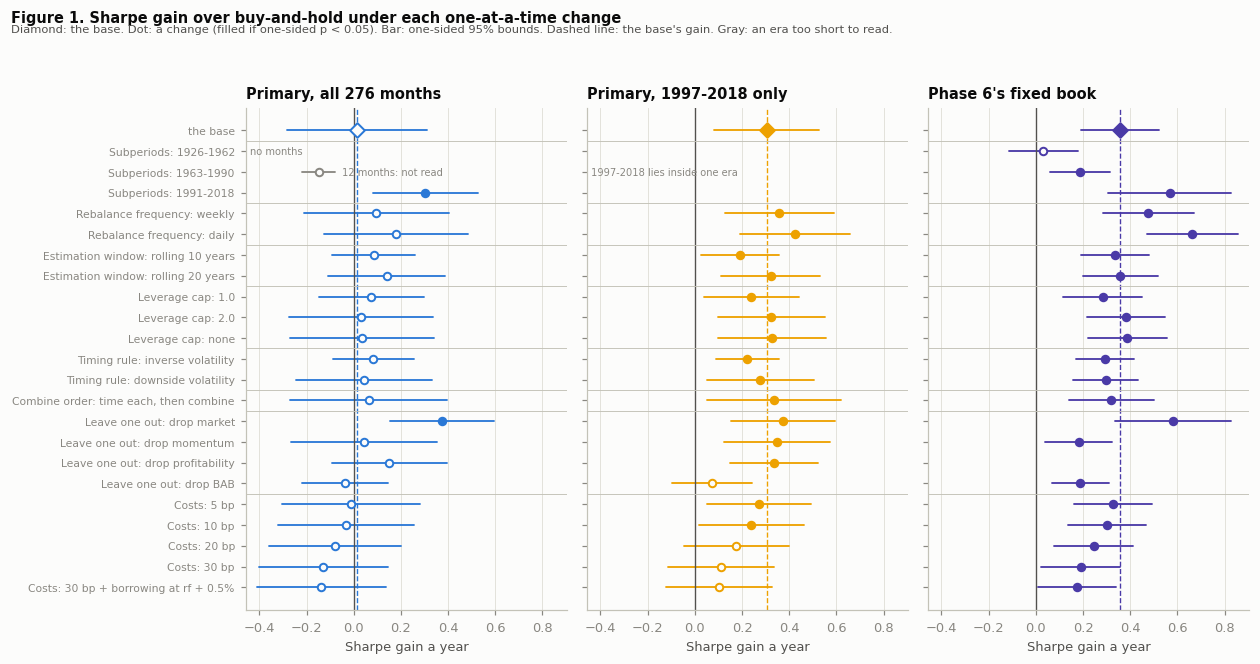

In [4]:
# Figure 1: every row of the robustness table, the gain with its one-sided 95% bounds
order = [("base", "")]
for c in rb.CHECKS:
    order += [(c, v) for v in dict.fromkeys(T.loc[(T["check"] == c) & ~T["is_base"], "variation"])]
ypos = {k: i for i, k in enumerate(order)}
readable = T[T["reading"].isin(["edge", "inconclusive", "no meaningful edge"])]
lo, hi = readable["lower"].min() - 0.05, readable["upper"].max() + 0.05
fig, axes = plt.subplots(1, 3, figsize=(11.5, 0.2 * len(order) + 1.4), sharey=True, sharex=True)
for ax, base in zip(axes, rb.BASES):
    d = T[(T["base"] == base) & ~T["is_base"]]
    items = [(("base", ""), BASE.loc[base])] + [((r["check"], r["variation"]), r) for _, r in d.iterrows()]
    for k, r in items:
        y = ypos[k]
        if pd.isna(r["gain"]):
            ax.text(lo + 0.02, y, "no months", fontsize=6.5, color=MUTED, va="center")
            continue
        short = r["reading"] == "too short to read"
        color = MUTED if short else BASE_COLOR[base]
        ax.plot([max(r["lower"], lo), min(r["upper"], hi)], [y, y], color=color, lw=1.2, solid_capstyle="round")
        ax.scatter(np.clip(r["gain"], lo, hi), y, s=46 if k[0] == "base" else 24, marker="D" if k[0] == "base" else "o",
                   color=color if (r["p"] < 0.05 and not short) else SURFACE, edgecolor=color, linewidth=1.3, zorder=3)
        if short:
            ax.text(r["upper"] + 0.03, y, f"{int(r['months'])} months: not read", fontsize=6.5, color=MUTED, va="center")
    if base == "primary_1997":
        ax.text(lo + 0.02, ypos[("subperiod", "1963-1990")], "1997-2018 lies inside one era", fontsize=6.5, color=MUTED, va="center")
    ax.axvline(0, color=INK2, lw=0.9)
    ax.axvline(BASE.loc[base, "gain"], color=BASE_COLOR[base], lw=0.9, ls="--")
    for i in range(1, len(order)):
        if order[i][0] != order[i - 1][0]:
            ax.axhline(i - 0.5, color=AXIS, lw=0.6)
    ax.set_title(BASE_NAME[base], color=INK)
    ax.set_xlim(lo, hi)
    ax.set_xlabel("Sharpe gain a year")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)), ["the base" if c == "base" else f"{CHECK_NAME[c]}: {v}" for c, v in order], fontsize=7)
axes[0].invert_yaxis()
fig.suptitle("Figure 1. Sharpe gain over buy-and-hold under each one-at-a-time change", x=0.01, y=0.995, ha="left", fontweight="bold", fontsize=9.5)
fig.text(0.01, 0.962, "Diamond: the base. Dot: a change (filled if one-sided p < 0.05). Bar: one-sided 95% bounds. Dashed line: the base's gain. "
         "Gray: an era too short to read.", fontsize=7.5, color=INK2)
fig.tight_layout(rect=(0, 0, 1, 0.945))

**Reading.**

- **The fixed book holds in seven checks and keeps its sign in the eighth.**
  - Every variation's interval sits above zero except the 1950–1962 era's (Figure 1, right).
  - The gains stay within about 0.2 of the base's +0.36. The exceptions are daily rebalancing (+0.66) and dropping the market (+0.58), both higher.
- **The primary as registered barely moves off zero** (Figure 1, left):
  - every interval spans zero except two, and those two leave out 1984: the 1991–2018 era and dropping the market;
  - the verdict "flips" in two checks: costs, where every row is negative, and leave-one-out, where dropping BAB gives −0.04.
- **Over 1997–2018 the primary sits at +0.2 to +0.4** under every change except two: dropping BAB (+0.07) and the two highest cost rows. Its verdict never flips.

## 3. Check by check

Each table shows the three bases one under the other. The columns are the Sharpe ratios (timed, buy-and-hold), the gain with its standard error, the one-sided p and the reading, the change in the gain from the base, both volatilities, and the mean size. The base row of each check repeats the base.

In [5]:
FMT = {"months": "{:.0f}", "sharpe": "{:.3f}", "bh_sharpe": "{:.3f}", "gain": "{:+.3f}", "se": "{:.3f}", "p": "{:.4f}",
       "change_in_gain": "{:+.3f}", "volatility": "{:.2%}", "bh_volatility": "{:.2%}", "mean_size": "{:.2f}", "share_capped": "{:.0%}",
       "turnover_a_year": "{:.2f}", "bh_turnover_a_year": "{:.2f}", "break_even": "{:.2%}", "cer_gain": "{:+.2%}",
       "max_drawdown": "{:.1%}", "bh_max_drawdown": "{:.1%}", "alpha": "{:+.2%}", "t_alpha": "{:.2f}"}
COLS = ["months", "sharpe", "bh_sharpe", "gain", "se", "p", "reading", "change_in_gain", "volatility", "bh_volatility", "mean_size"]

def check_table(check, extra=()):
    """The rows of one check, the three bases one under the other."""
    d = T[T["check"] == check].copy()
    d["base"] = d["base"].map(BASE_NAME)
    cols = COLS + list(extra)
    d = d.set_index(["base", "variation"])[cols]
    return d.style.format({k: v for k, v in FMT.items() if k in cols}, na_rep="–")

### 3a. Subperiods: does the edge live in one era?

The base run, scored on Phase 2's three eras. The primary scores nothing before 1984, because the ten-year training windows of Entry 6 come first. So its first era is empty, and its second holds only the twelve market-only months of 1984. The fixed book starts in December 1950.

In [6]:
check_table("subperiod")

**Reading.**

- **The fixed book's edge grows over time:**
  - 1950–1962: +0.03, inconclusive, and the placebo fails (Section 3i);
  - 1963–1990: +0.19, edge;
  - 1991–2018: +0.57, edge.
- **So the edge does not live in one era, but it does not live in the first one.** In the 1950s the mix was calm and steady (buy-and-hold's Sharpe ratio was 2.09), which left timing little to do.
- **The primary's eras repeat Entry 7.**
  - 1984 alone loses (−0.15 over 12 months, too short to read).
  - 1991–2018, which is 1997–2018 for this book, gains +0.30 and reads edge.

### 3b. Rebalance frequency: faster reacts sooner, but costs more

Weekly uses Phase 7's weekly M3 (a five-day forecast from the month-end fits). Daily trades at every close, on M3's one-day-ahead variance. Both are scored on calendar months, and a month counts only if the run holds every trading day of it. That rule drops January 1997 from the weekly primary, whose first week of 1997 opens before the new recipe.

In [7]:
check_table("frequency", ["turnover_a_year", "break_even"])

In [8]:
# Information, added after the run: where the daily gain sits, beside how autocorrelated each book's daily returns are
panel = load_dev()
eras = {"1950-1962": ("1950-12", "1962-12"), "1963-1990": ("1963-01", "1990-12"), "1991-2018": ("1991-01", "2018-12")}
rec = {"fixed": checks.recipes(panel, "fixed")}
rows = {}
for base, fam in (("fixed", "fixed"), ("primary_1997", None)):
    for v in ("monthly", "weekly", "daily"):
        d = RUNS.query("base == @base and check == 'frequency' and variation == @v").set_index("month")
        d.index = pd.PeriodIndex(d.index, freq="M")
        for era, (a, b) in eras.items():
            x = d.loc[a:b]
            if len(x) >= rb.ROBUST_RULES["min_era_months"]:
                rows.setdefault((BASE_NAME[base], era), {})[f"gain: {v}"] = checks.ev.sharpe(x["excess"]) - checks.ev.sharpe(x["bench_excess"])
book = checks.book(panel, rec["fixed"], "D")
mix = (panel.loc[book.positions.index.to_timestamp(), book.positions.columns] * book.positions.to_numpy()).sum(axis=1)
for era, (a, b) in eras.items():
    rows[(BASE_NAME["fixed"], era)]["daily AR(1) of the mix"] = mix.loc[a:b].autocorr()
    rows[(BASE_NAME["fixed"], era)]["daily AR(1): market / momentum / BAB"] = " / ".join(
        f"{panel[f].loc[a:b].autocorr():+.2f}" for f in ("mkt", "mom", "bab"))
display(pd.DataFrame(rows).T.style.format({"gain: monthly": "{:+.3f}", "gain: weekly": "{:+.3f}", "gain: daily": "{:+.3f}",
                                           "daily AR(1) of the mix": "{:+.2f}"}, na_rep="–"))

**Reading.**

- **Faster is better before costs, in every base.**

  | Base | Monthly | Weekly | Daily |
  |---|---|---|---|
  | Fixed book | +0.36 | +0.48 | +0.66 |
  | Primary, 1997–2018 | +0.30 | +0.36 | +0.43 |
  | Primary, all months (all inconclusive) | +0.01 | +0.10 | +0.18 |

- **It costs more.**
  - Turnover rises from 3–4 a year (monthly) to 7–10 (weekly) and 14–20 (daily).
  - The break-even cost falls with it. On the fixed book it is 64 bp monthly, 24 bp weekly and 17 bp daily; on the 1997–2018 cut, 47, 21 and 13 bp.
  - So the faster rules keep less of their larger paper gain once trading is priced.
- **A caveat, added after the run (the table above it).** The daily gain over monthly is largest in 1963–1990, when the fixed mix's daily returns were most autocorrelated:

  | Era | Daily over monthly | AR(1) of daily returns |
  |---|---|---|
  | 1963–1990 | +0.65 against +0.19 | 0.38 |
  | 1950–1962 | | 0.24 |
  | 1991–2018 | | 0.11 |

  - Paper factors built from stale closing prices have that kind of autocorrelation.
  - A daily GJR rule cuts size more after a down day, so it profits when a fall tends to continue the next day.
  - That part of the gain is not tradeable, so the daily row is more of an upper bound than the others.
- **One check that the daily row is not an engine artefact.** Its sizes and returns were rebuilt by hand on 51 days of the 1987 recipe and match to 10⁻¹². Its forecasts are unchanged when every return after a date is replaced.

### 3c. Estimation window: expanding against rolling 10 and 20 years

A rolling window changes both estimates made at each rebalance. The GARCH fit uses the last 2,520 or 5,040 trading days, and $c_t$ the last 120 or 240 monthly pairs. The screen and the mix weights keep their own windows.

In [9]:
check_table("window", ["share_capped"])

**Reading.**

- **The window barely matters on the fixed book:** +0.34 (10 years) and +0.36 (20 years), against +0.36 expanding.
- **On the 1997–2018 cut, ten years is weaker:** +0.19 against +0.30, still edge.
  - A ten-year $c_t$ moves with recent calm, which raises the mean size to about 1.05.
  - The cap then binds in 30% of months instead of 9%.
- **The primary as registered gains a little** (+0.09 and +0.14).
- **Steadier is not worse.** The expanding window, the frozen choice, is never beaten by much.

### 3d. Leverage cap: is the edge just leverage?

At a cap of 1.0 the timed run never borrows: it can only hold less than buy-and-hold, never more. $c_t$ is unchanged.

In [10]:
check_table("cap", ["share_capped", "turnover_a_year"])

**Reading.**

- **No: the edge is not just leverage.**
  - With the cap at 1.0, the fixed book still gains +0.28 (p 0.003), and the 1997–2018 cut +0.24 (p 0.025).
  - The timed run then holds less than buy-and-hold in every month (mean size 0.82 on the fixed book), yet earns a higher Sharpe ratio. Cutting risk in wild months does the work.
- **Leverage adds a little.** Moving from cap 1.0 to 1.5 adds about +0.07, and removing the cap adds +0.03 more. A cap of 2 binds in only 6% of months.
- **For the primary as registered, the order reverses.** Cap 1.0 gives +0.07, and cap 1.5 gives +0.01. In 1984 the timed run levered up to 1.5 after a calm 1983 and lost (Entry 7), and a cap of 1.0 limits that.

### 3e. Timing rule: how strongly to react

Inverse variance halves the size when volatility rises by about 41%. Inverse volatility reacts half as strongly. Downside volatility reacts to the variance of down days only.

In [11]:
check_table("rule", ["share_capped"])

**Reading.**

- **The data favour the strongest reaction, but not by much.**
  - On the fixed book, inverse variance gains +0.36 against +0.29 for both volatility rules.
  - On the 1997–2018 cut it gains +0.30 against +0.22 (inverse volatility) and +0.28 (downside).
  - All of these read "edge".
- **These are point estimates, not a test of one rule against another.** The gaps are well inside one standard error of a gain.
- **For the primary as registered, inverse volatility is best** (+0.08, inconclusive). Its milder reaction levered less in 1984.

### 3f. Combine order: time the mix, or time each factor and then combine?

When each factor is timed alone, it gets its own forecast, its own real-time $c_t$ and its own 1.5 cap. Its position is its mix weight times its own size. The benchmark is unchanged.

In [12]:
check_table("order", ["share_capped", "turnover_a_year"])

**Reading.**

- **Neither order wins clearly:**

  | Base | Combine, then time | Time each, then combine |
  |---|---|---|
  | Fixed book | +0.36 | +0.32 |
  | Primary, 1997–2018 | +0.30 | +0.34 |

  All four read "edge".
- **Timing each factor binds the caps far more often.** On the fixed book, some factor sits at its cap in 62% of months, against 25% for the mix.
- **Timing the combined portfolio is simpler and at least as good on the long book.** The plan's choice (combine first) stands.

### 3g. Leave one out: does one factor carry the whole result?

Each asset the book holds is dropped from every year-end in turn, and the recipe is rebuilt on the rest.
- **The fixed book:** market, momentum or BAB. Dropping BAB gives Phase 4's paper market + momentum book, the ETF track's paper twin.
- **The primary:** market, momentum, profitability or BAB. A year left empty is cash. Dropping the market empties 1984, so that row scores 264 months.

The second table is information: each asset's share of buy-and-hold's variance, $w_i(\Sigma w)_i / w'\Sigma w$, averaged over the recipes held.

In [13]:
check_table("leave_one_out")

In [14]:
r = RISK.copy()
r["family"] = r["family"].map({"screened": "screened (the primary)", "fixed": "fixed book"})
display(r.set_index(["family", "method", "asset"]).style.format({"mean_share": "{:.0%}", "max_share": "{:.0%}"}))

**Reading.**

- **On the fixed book, no single factor carries the result.**
  - Dropping momentum or BAB halves the gain, to +0.18 and +0.19. Both still read "edge".
  - **The ETF track's paper twin** (market + momentum) gains +0.19 (p 0.005).
  - Dropping the market raises the gain to +0.58. The market is the leg that timing helps least, as in Phase 6, where the market timed alone gained +0.03.
- **On the primary, BAB carries the 1997–2018 result.**
  - Without BAB the gain falls to +0.07 (inconclusive) over 1997–2018, and to −0.04 over all months.
  - Dropping momentum or profitability changes little.
  - Dropping the market reads "edge", but only because it removes 1984.
- **Risk shares: the plan expected momentum to dominate under equal weights. Here the market does.**

  | Fixed book | Market | Momentum | BAB |
  |---|---|---|---|
  | Equal weights | 56% | 40% | 3% |
  | Inverse-volatility weights | 22% | 53% | 24% |

  Under the primary's inverse-volatility weights, momentum carries about half of buy-and-hold's variance, and BAB and the market split the rest.

### 3h. Costs: does it survive real frictions?

κ is charged per unit traded on every instrument, in both runs. It prices trading each factor as a unit, not the trading inside the factor. The last row adds borrowed cash at rf + 0.5% a year. Figure 2 omits that row.

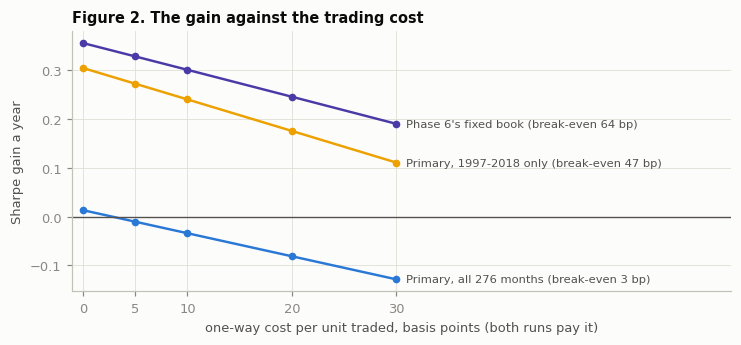

In [15]:
# Figure 2: the gain as the cost per trade rises (trading cost only), with each base's break-even
fig, ax = plt.subplots(figsize=(6.8, 3.2))
for base in rb.BASES:
    d = T[(T["base"] == base) & (T["check"] == "costs") & ~T["variation"].str.contains("borrow")].copy()
    d["kappa"] = d["variation"].str.extract(r"(\d+) bp")[0].astype(float)
    d = d.sort_values("kappa")
    ax.plot(d["kappa"], d["gain"], color=BASE_COLOR[base], marker="o", ms=4, lw=1.6)
    ax.annotate(f"{BASE_NAME[base]} (break-even {BASE.loc[base, 'break_even'] * 1e4:.0f} bp)", (d["kappa"].iloc[-1], d["gain"].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", fontsize=7.5, color=INK2, va="center")
ax.axhline(0, color=INK2, lw=0.9)
ax.set_xlim(-1, 62)
ax.set_xticks([0, 5, 10, 20, 30])
ax.set_xlabel("one-way cost per unit traded, basis points (both runs pay it)")
ax.set_ylabel("Sharpe gain a year")
ax.set_title("Figure 2. The gain against the trading cost")
fig.tight_layout()

In [16]:
check_table("costs", ["break_even"])

In [17]:
# Entry 3's short-fee stress on the ETF track (SPY + MTUM tilt, after costs): 20 development months
cols = ["costs", "months", "first", "sharpe", "bh_sharpe", "gain", "se", "p", "reading", "volatility", "bh_volatility"]
display(STRESS[cols].set_index("costs").style.format({"sharpe": "{:.3f}", "bh_sharpe": "{:.3f}", "gain": "{:+.3f}", "se": "{:.3f}",
                                                       "p": "{:.3f}", "volatility": "{:.2%}", "bh_volatility": "{:.2%}"}))

,months,first,sharpe,bh_sharpe,gain,se,p,reading,volatility,bh_volatility
costs,,,,,,,,,,
base: SPY short fee 0.25% a year,20,2017-05,1.006,0.918,+0.088,0.170,0.303,inconclusive,6.63%,6.29%
stress: SPY short fee 1% a year,20,2017-05,0.969,0.876,+0.094,0.170,0.290,inconclusive,6.62%,6.29%


**Reading.**

- **The fixed book survives 30 bp.** Its gain is +0.19 (p 0.03), and +0.18 (p 0.04) once borrowing is charged. It breaks even at 64 bp one-way.
- **The 1997–2018 cut survives 10 bp** (+0.24, edge). It turns inconclusive at 20 bp (+0.18) and 30 bp (+0.11), and breaks even at 47 bp.
- **The primary as registered breaks even at 3 bp.** Its point estimate is negative from the first cost row. Turnover is the same as the others' (3 a year); the gain is simply too small to pay for any trading.
- **Entry 3's short-fee stress** (the ETF track's SPY + MTUM book, 20 months) moves the gain from +0.088 to +0.094.
  - A higher fee costs buy-and-hold slightly more than the timed run, because buy-and-hold carries the full short.
  - Twenty months cannot say more.

### 3i. Placebo: does it beat random timing?

Each recipe's forecast is shuffled in time, 1,000 times (seeds 0–999, as in Phases 6 and 7), and sizes and $c_t$ are rerun. The rule is Entry 2's: the real spanning α must beat 95% of the shuffled ones. The share of shuffled Sharpe gains the real gain beats is reported beside it, as information, and so are the eras.

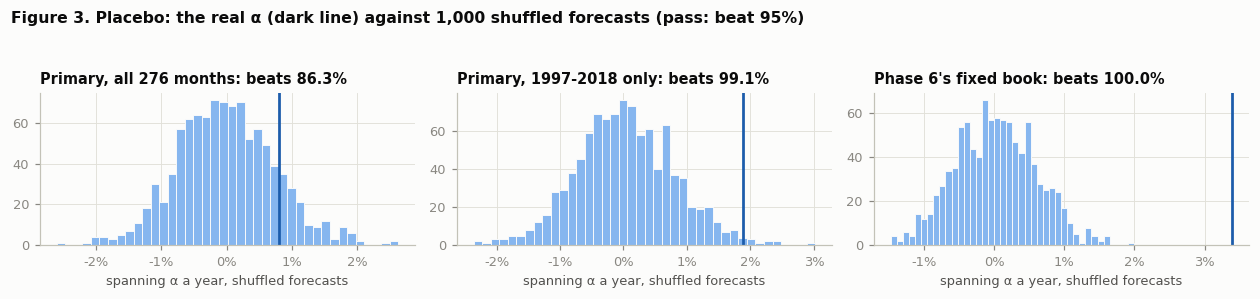

In [18]:
# Figure 3: the real spanning alpha against 1,000 shuffled forecasts, for each book family on its base months
fig, axes = plt.subplots(1, 3, figsize=(11.5, 2.7))
for ax, base in zip(axes, rb.BASES):
    fam = "screened" if base != "fixed" else "fixed"
    real = RUNS.query("base == @base and check == 'frequency' and variation == 'monthly'").set_index("month")
    D = DRAWS.loc[fam][real.index]
    b = real["bench_excess"]
    alphas = [checks.ev.alpha(D.loc[i].astype(float), b) for i in D.index]
    a = checks.ev.alpha(real["excess"], b)
    ax.hist(alphas, bins=40, color=LIGHT, edgecolor=SURFACE, linewidth=0.6)
    ax.axvline(a, color=DARK, lw=1.8)
    share = P.query("base == @base and months_set == 'all months'")["alpha_share"].iloc[0]
    ax.set_title(f"{BASE_NAME[base]}: beats {share:.1%}")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("spanning α a year, shuffled forecasts")
fig.suptitle("Figure 3. Placebo: the real α (dark line) against 1,000 shuffled forecasts (pass: beat 95%)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))

In [19]:
p = P.copy()
p["base"] = p["base"].map(BASE_NAME)
display(p.set_index(["base", "months_set"]).style.format({"months": "{:.0f}", "alpha": "{:+.2%}", "alpha_share": "{:.1%}",
                                                          "gain": "{:+.3f}", "gain_share": "{:.1%}"}))

**Reading.**

- **The fixed book beats all 1,000 shuffles**, and the 1997–2018 cut beats 99.1%. The timing, not just the average size, earns their gains.
- **The primary as registered fails, at 86.3%,** as in Phase 7.
- **By era, the fixed book fails in 1950–1962** (92.2%) and passes in 1963–1990 (97.9%) and 1991–2018 (100%). This matches the subperiods: the earliest era has no real edge.

## 4. Crisis case studies

**Why.** A strategy that cuts risk after the crash and misses the recovery can look fine on average and still be painful to hold. 2020 and 2022 sit in the holdout and wait for Phase 9.

**The episodes.**
- **Peak:** the market's highest close (total return) in the first year.
- **Trough:** its lowest close after the peak, by the end of the last year.
- **The window:** 6 months before the peak to 12 months after the trough.

**The runs shown** (each only where it holds a position on every trading day of the window):
- the primary (2000–2002 and 2008–2009 only: it holds cash in 1985–1996);
- Phase 6's fixed book (from 1950);
- momentum alone, under two rules:
  - Barroso and Santa-Clara's: 126-day variance, 12% target, no cap. It needs six months of data;
  - the frozen rule: M3, real-time $c_t$, cap 1.5. It needs 20 years of history;
- the market alone, under Barroso and Santa-Clara's rule.

In 1929–1932 only Barroso and Santa-Clara's rule exists.

**The panels.** Each column is one book, and the rows are the plan's four:
- price: buy-and-hold's value;
- σ̂: the forecast in force, as annualized volatility, beside the realized 22-day volatility in gray;
- the size $w_t$;
- growth relative to cash, timed against buy-and-hold.

The shaded span runs from peak to trough, and the dots are buy-and-hold's five worst days in it.

**The three questions.** The table under each panel answers them:
1. **Before or after the worst days?** The size six months before the peak, against the size on the five worst days, and each run's loss on those days.
2. **Did it miss the rebound?** Growth over the fall and over the 12 months after the trough, timed against buy-and-hold.
3. **How much did the cap and costs matter?** Growth over the window's whole calendar months: as run, with no cap or another cap, and at 30 bp a trade. Questions 1 and 2 are read day by day.

In [20]:
s = Q.drop_duplicates("episode")[["episode", "peak", "trough", "market_fall"]].set_index("episode")
s["window"] = [f"{(p - pd.DateOffset(months=6)):%b %Y} to {(t + pd.DateOffset(months=12)):%b %Y}" for p, t in zip(s["peak"], s["trough"])]
s["shown"] = [", ".join(dict.fromkeys(f"{BOOK_NAME[b]}" for b in Q.loc[Q["episode"] == ep, "book"])) for ep in s.index]
display(s.style.format({"peak": "{:%d %b %Y}", "trough": "{:%d %b %Y}", "market_fall": "{:.0%}"}))

,peak,trough,market_fall,window,shown
episode,,,,,
1929-1932,03 Sep 1929,08 Jul 1932,-84%,Mar 1929 to Jul 1933,"Momentum alone, Market alone"
October 1987,25 Aug 1987,04 Dec 1987,-33%,Feb 1987 to Dec 1988,"Phase 6's fixed book, Momentum alone, Market alone"
2000-2002,24 Mar 2000,09 Oct 2002,-49%,Sep 1999 to Oct 2003,"The primary (screened book), Phase 6's fixed book, Momentum alone, Market alone"
2008-2009,09 Oct 2007,09 Mar 2009,-55%,Apr 2007 to Mar 2010,"The primary (screened book), Phase 6's fixed book, Momentum alone, Market alone"


In [21]:
def crisis_panel(episode, number, books):
    """The plan's four rows for one episode, day by day: price, σ̂, size, growth against buy-and-hold."""
    q = Q[Q["episode"] == episode]
    peak, trough = q["peak"].iloc[0], q["trough"].iloc[0]
    start, end = peak - pd.DateOffset(months=6), trough + pd.DateOffset(months=12)
    fig, axes = plt.subplots(4, len(books), figsize=(11.5, 7.6), sharex=True, squeeze=False,
                             gridspec_kw={"height_ratios": [1.1, 1, 0.8, 1.1]})
    for j, book in enumerate(books):
        runs_ = PATHS[(PATHS["episode"] == episode) & (PATHS["book"] == book)]
        versions = [v for v in ("frozen", "bsc") if v in set(runs_["version"])]
        ref = runs_[runs_["version"] == versions[0]].set_index("date")
        realized = np.sqrt((ref["bench_ret"] ** 2).rolling(22).sum() * 252 / 22).loc[start:]     # the two months before: its warm-up
        ref = ref.loc[start:]
        worst = pd.to_datetime(q.loc[q["book"] == book, "worst_days"].iloc[0].split(", "))
        bh = ref["bench_value"] / ref["bench_value"].iloc[0]
        ax = axes[0, j]
        ax.plot(bh.index, bh, color=INK2, lw=1.2)
        ax.scatter(worst, bh.loc[worst], s=16, color=INK, zorder=3)
        ax.set_title(BOOK_NAME[book])
        ax = axes[1, j]
        ax.plot(realized.index, realized, color=MUTED, lw=0.8)
        for v in versions:
            d = runs_[runs_["version"] == v].set_index("date").loc[start:]
            ann = np.sqrt(d["forecast"] * (12 if v == "bsc" else 252 / 22))
            ax.plot(d.index, ann, color=VERSION_COLOR[v], lw=1.4, drawstyle="steps-post")
            axes[2, j].plot(d.index, d["size"], color=VERSION_COLOR[v], lw=1.4, drawstyle="steps-post")
            g = d["value"] / d["value"].iloc[0]
            axes[3, j].plot(g.index, g, color=VERSION_COLOR[v], lw=1.6)
        ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
        axes[2, j].axhline(1.0, color=INK2, lw=0.8, ls="--")
        if "frozen" in versions:
            axes[2, j].axhline(1.5, color=MUTED, lw=0.8, ls=":")
        axes[3, j].plot(bh.index, ref["bench_value"] / ref["bench_value"].iloc[0], color=INK2, lw=1.2)
        for i in range(4):
            axes[i, j].axvspan(peak, trough, color=AXIS, alpha=0.25, lw=0)
    axes[0, 0].set_ylabel("price: buy-and-hold\n(window start = 1)")
    axes[1, 0].set_ylabel("volatility, a year")
    axes[2, 0].set_ylabel("size w_t")
    axes[3, 0].set_ylabel("growth against cash\n(window start = 1)")
    for ax in axes[3]:
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=6))
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    handles = [Line2D([], [], color=BLUE, lw=1.6, label=VERSION_NAME["frozen"]), Line2D([], [], color=AMBER, lw=1.6, label=VERSION_NAME["bsc"]),
               Line2D([], [], color=INK2, lw=1.2, label="buy-and-hold"), Line2D([], [], color=MUTED, lw=0.8, label="realized 22-day volatility"),
               Line2D([], [], color=INK, marker="o", lw=0, ms=4, label="buy-and-hold's 5 worst days")]
    used = set(PATHS.loc[(PATHS["episode"] == episode) & PATHS["book"].isin(books), "version"])
    handles = [h for h in handles if not (h.get_label() == VERSION_NAME["frozen"] and "frozen" not in used)]
    fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=5, fontsize=7.5)
    fig.suptitle(f"Figure {number}. {episode}: market peak {peak:%d %b %Y}, trough {trough:%d %b %Y} (shaded)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.93))


def crisis_table(episode, books):
    """The three questions for each run in the episode."""
    q = Q[(Q["episode"] == episode) & Q["book"].isin(books)].copy()
    q["run"] = [f"{BOOK_NAME[b]}: {'B&SC' if v == 'bsc' else 'frozen'}" for b, v in zip(q["book"], q["version"])]
    cols = {"lead_size": "1. size, 6 months before", "worst_size": "1. size on the 5 worst days",
            "worst_timed": "1. loss on them: timed", "worst_bench": "1. loss on them: buy-and-hold",
            "fall_timed": "2. fall: timed", "fall_bench": "2. fall: buy-and-hold", "fall_size": "2. size in the fall",
            "rebound_timed": "2. rebound: timed", "rebound_bench": "2. rebound: buy-and-hold", "rebound_size": "2. size in the rebound",
            "window: as run": "3. window: as run", "window: no cap": "3. no cap", "window: cap 1.0": "3. cap 1.0",
            "window: cap 1.5": "3. cap 1.5", "window: 30 bp": "3. at 30 bp", "window_bench": "3. window: buy-and-hold"}
    # Questions 1-2 run day by day; question 3 over the window's whole calendar months
    t = q.set_index("run")[[c for c in cols if c in q]].rename(columns=cols).T
    pct = [k for k in t.index if "size" not in k]
    return t.style.format("{:+.1%}", subset=pd.IndexSlice[pct, :], na_rep="–").format(
        "{:.2f}", subset=pd.IndexSlice[[k for k in t.index if "size" in k], :], na_rep="–")

### 4a. 1929–1932

The market lost 84% from 3 September 1929 to 8 July 1932. No frozen-rule book exists yet: the market, momentum and BAB have three to six years of data. So both columns use Barroso and Santa-Clara's rule. This crisis also contains momentum's July–August 1932 crash, right after the trough.

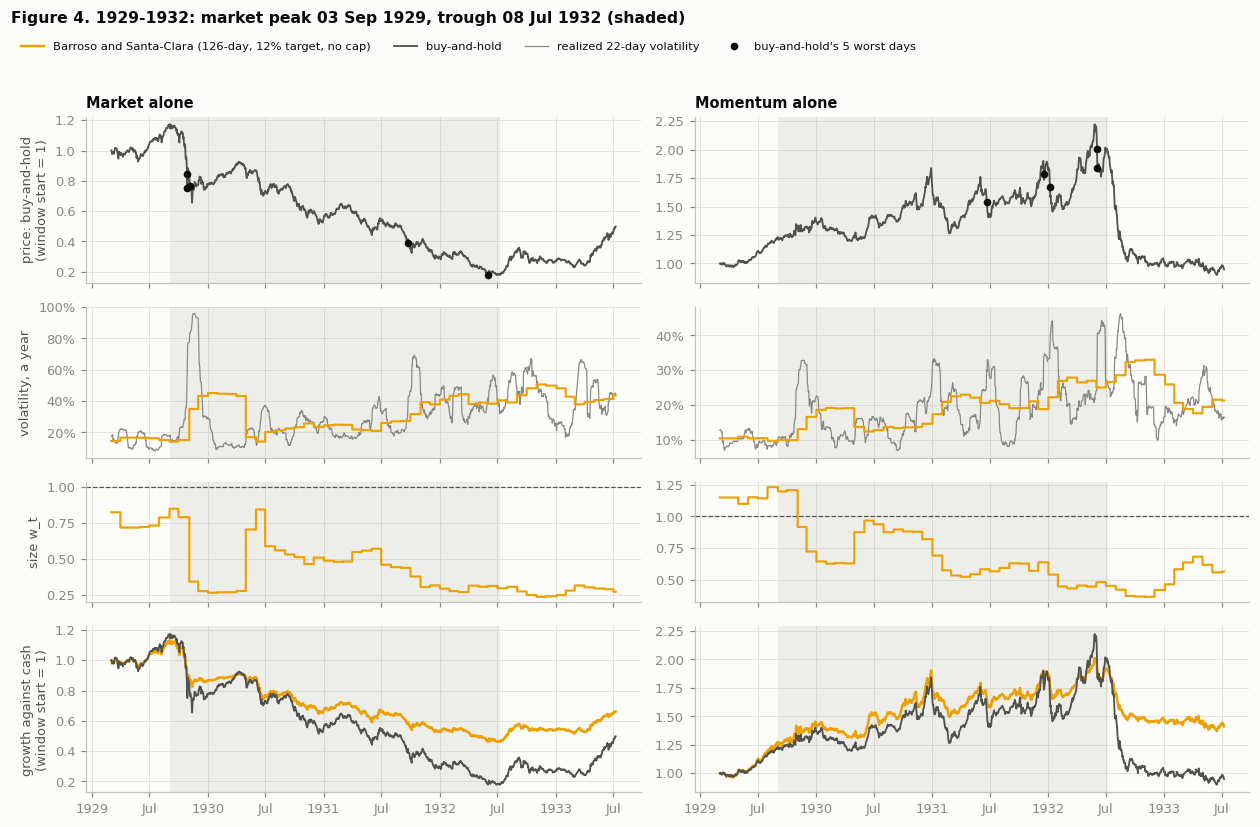

In [22]:
crisis_panel("1929-1932", 4, ["mkt", "mom"])

In [23]:
crisis_table("1929-1932", ["mkt", "mom"])

run,Momentum alone: B&SC,Market alone: B&SC
"1. size, 6 months before",1.15,0.75
1. size on the 5 worst days,0.54,0.53
1. loss on them: timed,-16.0%,-25.0%
1. loss on them: buy-and-hold,-29.9%,-46.0%
2. fall: timed,+48.8%,-59.2%
2. fall: buy-and-hold,+59.4%,-84.9%
2. size in the fall,0.69,0.45
2. rebound: timed,-25.6%,+43.7%
2. rebound: buy-and-hold,-51.7%,+179.8%
2. size in the rebound,0.49,0.28


**Reading.**

- **The market alone cut risk after the crash, not before.**
  - Its size for October 1929, set at the end of September, was 0.79. It fell to 0.34 only for November.
  - On the five worst days it held 0.53 on average and took 54% of buy-and-hold's loss.
  - Over the fall it lost 59%, against 85% for buy-and-hold.
- **Then it missed the rebound.** It held about 0.28 into the 1932–33 rally and gained 44%, against 180%.
- **Momentum alone rose through the fall, then crashed in the rebound.**
  - The rule had cut momentum to about 0.45 by mid-1932, as momentum's own volatility rose.
  - So it lost 26% over the 12 months after the trough, against 52% for buy-and-hold.
  - Over the window, managed momentum gained 43%, against −3%.
- **The cap and costs.** A cap of 1.0 would have cost managed momentum 7 points over the window, because it was levered to 1.2 before the crash. The market never sized above 1, so the cap did not touch it. 30 bp cost less than 1 point.

### 4b. October 1987

The market peaked on 25 August 1987 and fell 33% to 4 December, with Black Monday (19 October) in between. The primary holds cash in 1987. The table also shows the market alone.

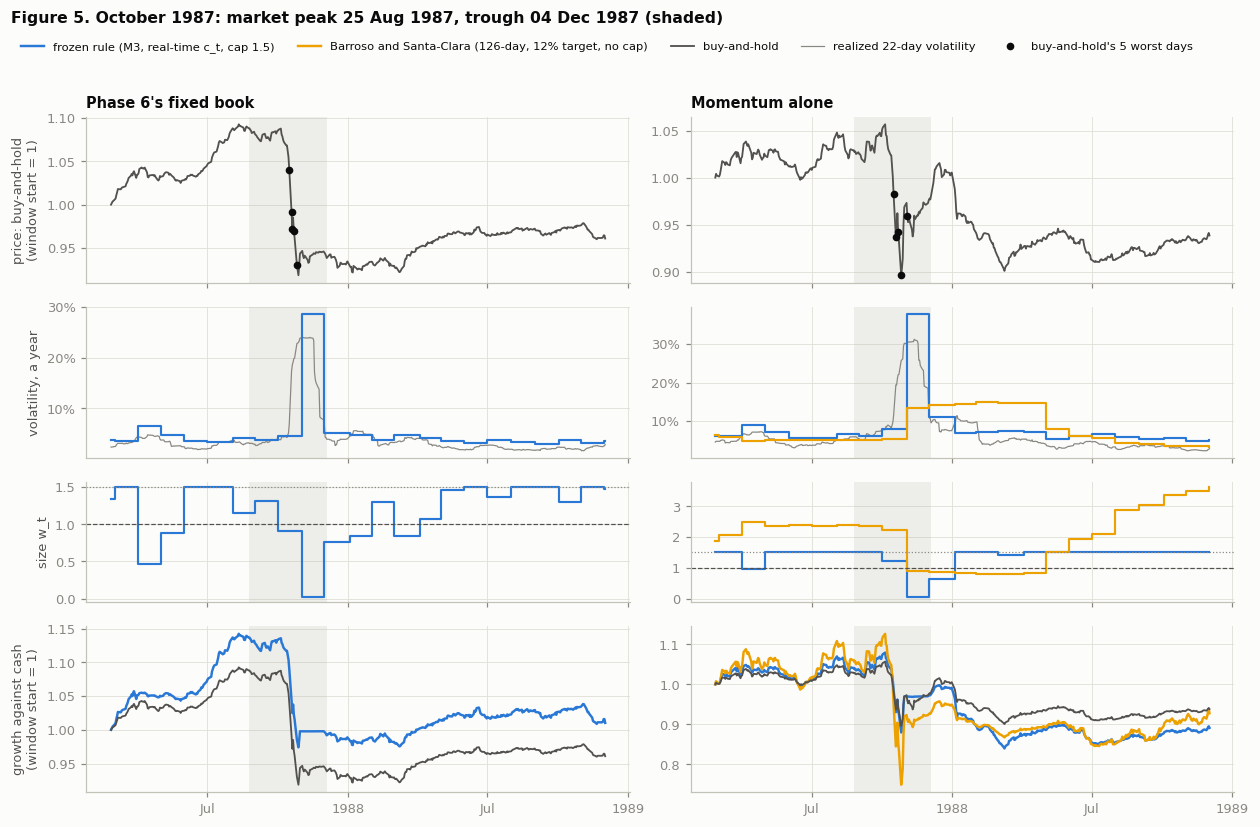

In [24]:
crisis_panel("October 1987", 5, ["fixed", "mom"])

In [25]:
crisis_table("October 1987", ["fixed", "mom", "mkt"])

run,Phase 6's fixed book: frozen,Momentum alone: B&SC,Market alone: B&SC,Momentum alone: frozen
"1. size, 6 months before",1.18,2.34,0.87,1.41
1. size on the 5 worst days,0.92,1.96,0.77,0.98
1. loss on them: timed,-11.8%,-32.4%,-30.9%,-15.6%
1. loss on them: buy-and-hold,-12.9%,-14.0%,-38.6%,-14.0%
2. fall: timed,-12.8%,-12.4%,-26.1%,-6.3%
2. fall: buy-and-hold,-13.8%,-4.7%,-34.2%,-4.7%
2. size in the fall,0.79,1.83,0.71,0.96
2. rebound: timed,+1.9%,-0.2%,+6.0%,-8.6%
2. rebound: buy-and-hold,+2.4%,-4.3%,+20.2%,-4.3%
2. size in the rebound,1.25,1.91,0.60,1.43


**Reading.**

- **A crash out of calm: the monthly rule cut only after it.**
  - The fixed book's size for October was set at the 30 September close, at 0.92, after months of calm at 1.15–1.5.
  - It took 91% of buy-and-hold's loss on the worst days (16–26 October).
  - Its November size was 0.02.
- **The window still ends ahead** (−0.1% against −4.7%). The fixed book had been levered to 1.5 in the calm rally before the crash, so it entered the fall ahead.
- **It did not miss the rebound:** it held 1.25 in the following year and grew 1.9%, against 2.4%.
- **Leverage hurt managed momentum.**
  - The frozen rule held momentum at 1.22 into October and took 1.12 times buy-and-hold's loss on the worst days.
  - Barroso and Santa-Clara's uncapped rule held it at 2.23 and took 2.3 times buy-and-hold's loss on those days.
  - A 1.5 cap would have saved that rule 2.4 points over the window, and a cap of 1.0, 5.6.
- **The market alone** (Barroso and Santa-Clara) held 0.77 on the worst days and took 80% of the loss. It then gained 6% in the rebound, against 20%.

### 4c. 2000–2002

The market lost 49% from 24 March 2000 to 9 October 2002. Over the same span the primary's and the fixed book's buy-and-hold gained, with BAB, profitability and momentum rising as technology stocks fell.

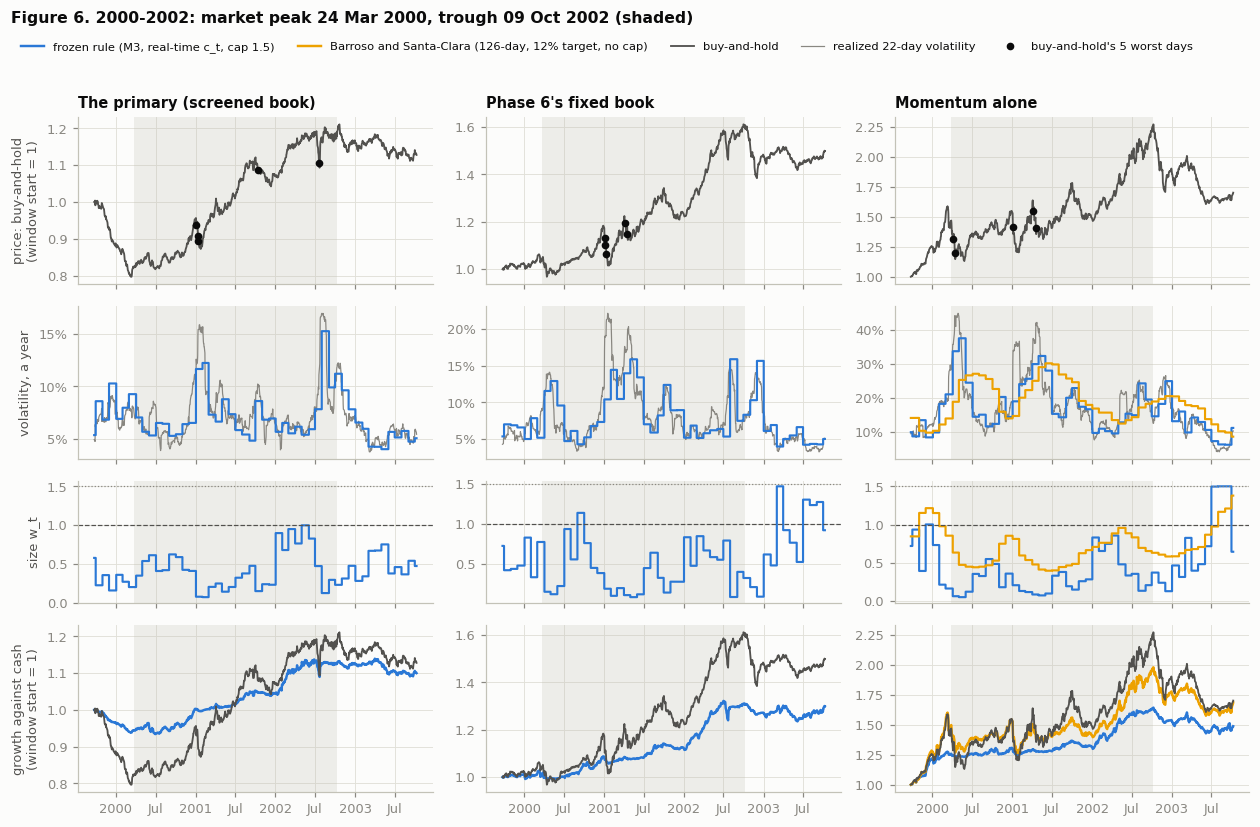

In [26]:
crisis_panel("2000-2002", 6, ["primary", "fixed", "mom"])

In [27]:
crisis_table("2000-2002", ["primary", "fixed", "mom", "mkt"])

run,The primary (screened book): frozen,Phase 6's fixed book: frozen,Momentum alone: B&SC,Market alone: B&SC,Momentum alone: frozen
"1. size, 6 months before",0.27,0.54,1.03,0.68,0.60
1. size on the 5 worst days,0.17,0.16,0.61,0.50,0.10
1. loss on them: timed,-1.4%,-2.2%,-18.0%,-12.0%,-3.2%
1. loss on them: buy-and-hold,-8.8%,-13.6%,-29.2%,-23.7%,-29.2%
2. fall: timed,+19.2%,+28.7%,+33.3%,-34.9%,+30.8%
2. fall: buy-and-hold,+43.2%,+52.2%,+56.1%,-54.1%,+56.1%
2. size in the fall,0.43,0.43,0.62,0.55,0.31
2. rebound: timed,-2.3%,-0.5%,-14.8%,+19.8%,-9.4%
2. rebound: buy-and-hold,-4.3%,-5.9%,-25.1%,+38.5%,-25.1%
2. size in the rebound,0.46,0.79,0.80,0.52,0.72


**Reading.**

- **Risk was cut before the worst days.**
  - Volatility built up through 2000.
  - The primary held 0.17, the fixed book 0.16 and momentum (frozen rule) 0.10 on buy-and-hold's five worst days.
  - They took 11–16% of buy-and-hold's loss on those days.
- **The cost was the upside.** The mixes rose in this crash, and the timed runs, kept small, rose less:
  - the primary: +19% against +43% over the fall;
  - the fixed book: +29% against +52%;
  - momentum: +31% against +56%.
- **The rebound was a fall for these books,** and the timed runs fell less.
  - The fixed book lost 0.5%, against 5.9%.
  - Momentum lost 9%, against 25%.
- **The cap and costs.**
  - Under the frozen rule they moved the window by at most 5 points. 30 bp cost the fixed book 5 of its 31 points.
  - A cap of 1.0 would have cost Barroso and Santa-Clara's momentum 8 points.

### 4d. 2008–2009

The market lost 55% from 9 October 2007 to 9 March 2009. Momentum's March–May 2009 crash falls in the rebound.

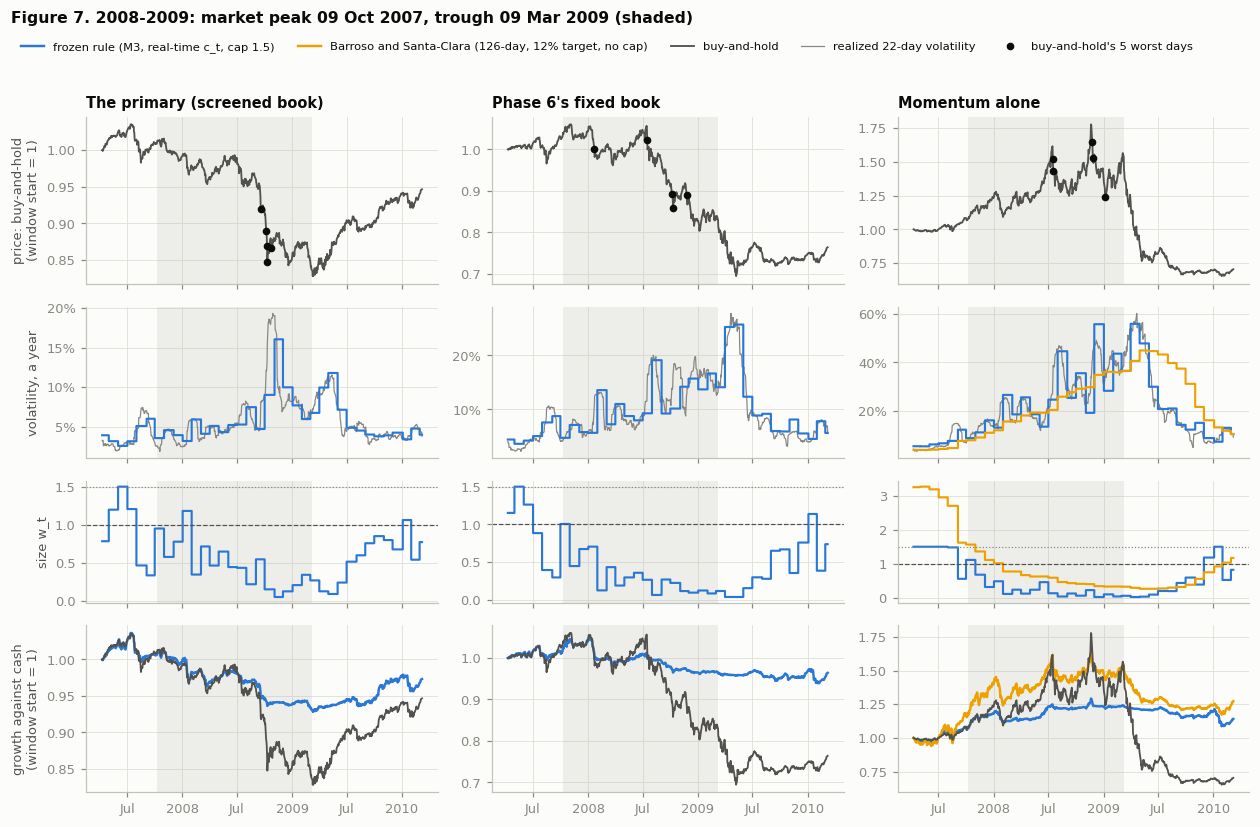

In [28]:
crisis_panel("2008-2009", 7, ["primary", "fixed", "mom"])

In [29]:
crisis_table("2008-2009", ["primary", "fixed", "mom", "mkt"])

run,The primary (screened book): frozen,Phase 6's fixed book: frozen,Momentum alone: B&SC,Market alone: B&SC,Momentum alone: frozen
"1. size, 6 months before",0.92,0.92,2.77,1.04,1.34
1. size on the 5 worst days,0.23,0.31,0.46,0.40,0.17
1. loss on them: timed,-2.1%,-3.8%,-14.0%,-15.1%,-5.3%
1. loss on them: buy-and-hold,-9.5%,-13.0%,-28.7%,-40.0%,-28.7%
2. fall: timed,-7.7%,-5.4%,+29.6%,-28.7%,+14.7%
2. fall: buy-and-hold,-17.4%,-19.8%,+41.9%,-55.8%,+41.9%
2. size in the fall,0.47,0.31,0.68,0.52,0.26
2. rebound: timed,+4.6%,-0.2%,-17.0%,+21.4%,-7.9%
2. rebound: buy-and-hold,+13.3%,-7.9%,-54.3%,+75.4%,-54.3%
2. size in the rebound,0.55,0.42,0.49,0.45,0.45


**Reading.**

- **Risk was cut before the worst days.** Volatility rose from mid-2007, and on buy-and-hold's five worst days (mostly September–November 2008) the average size was down:
  - the primary to 0.23, the fixed book to 0.31, momentum (frozen rule) to 0.17;
  - they took 22%, 29% and 18% of buy-and-hold's loss on its five worst days.
- **The fall, timed against buy-and-hold:**
  - the primary: −8% against −17%;
  - the fixed book: −5% against −20%.
- **The rebound split by book.**
  - The primary held about 0.55 and gained 4.6%, against 13.3%: it missed part of the rally.
  - The fixed book and momentum faced momentum's crash instead. Small, they lost far less: the fixed book −0.2% against −7.9%, and momentum −8% against −54%.
  - The market alone (Barroso and Santa-Clara) missed most of the rally: +21% against +75%.
- **Over the window:**
  - the fixed book: −2% against −22%;
  - momentum (frozen rule): +16% against −29%.
- **The cap and costs moved the window by under 3 points,** except for Barroso and Santa-Clara's momentum. It was levered near 3 in mid-2007, and a cap of 1.5 or 1.0 would have cost it 8 or 18 points of the window's gain.

### 4e. Momentum's two crashes: did the managed version step aside in time?

Barroso and Santa-Clara's winners-minus-losers portfolio lost 91.59% in July–August 1932 and 73.42% in March–May 2009. This project's momentum is French's UMD, a broader portfolio, so its losses are different numbers.

In [30]:
c = CRASH.set_index("crash")
show = pd.DataFrame({"Barroso and Santa-Clara's WML (published)": c["published_wml"], "momentum (UMD) at size 1": c["bench"],
                     "managed: Barroso and Santa-Clara's rule": c["bsc"], "its size at the start": c["bsc_size_first"],
                     "managed: frozen rule": c.get("frozen"), "its size at the start ": c.get("frozen_size_first")}).T
display(show.style.format("{:+.1%}", subset=pd.IndexSlice[[i for i in show.index if "size" not in i], :], na_rep="–").format(
    "{:.2f}", subset=pd.IndexSlice[[i for i in show.index if "size" in i], :], na_rep="–"))

crash,July-August 1932,March-May 2009
Barroso and Santa-Clara's WML (published),-91.6%,-73.4%
momentum (UMD) at size 1,-0.46,-0.46
managed: Barroso and Santa-Clara's rule,-21.7%,-15.4%
its size at the start,0.45,0.33
managed: frozen rule,–,-2.1%
its size at the start,–,0.06


**Reading.**

- **Yes, partly, in both crashes.**
- **July–August 1932.** UMD lost 46%. Barroso and Santa-Clara's rule had cut the size to 0.45 by the end of June, as momentum's volatility rose, and lost 22%.
- **March–May 2009.** UMD lost 46%. Barroso and Santa-Clara's rule was at 0.33 and lost 15%. The frozen rule, whose GJR forecast had risen faster, was at 0.06 and lost 2%.
- **The pattern matches Barroso and Santa-Clara's account.** Momentum's crashes follow months of high momentum volatility, so a volatility rule is already small when they come.

### 4f. The three questions, across the four crises

1. **Before or after the worst days?** It depends on whether volatility warned first.
   - **2000–2002 and 2008–2009:** volatility rose for months.
     - The frozen-rule runs held 0.1–0.3 on average on the worst days and took 11–29% of buy-and-hold's loss on them.
     - Barroso and Santa-Clara's slower rule held 0.4–0.6 and took 38–62%.
   - **October 1929 and October 1987:** the crash came out of calm, and the monthly rule was still at 0.8–0.9 for the market and the fixed book (1.2–2.2 for momentum). It cut only for the month after.
2. **Did it miss the rebound?** For the market, yes:
   - +44% against +180% after 1932;
   - +6% against +20% after 1987;
   - +21% against +75% after 2009.

   The mixes and momentum did not, because their rebounds were momentum crashes, and being small helped. The primary missed part of 2009's rally (+4.6% against +13.3%).
3. **How much did the cap and costs matter?**
   - Under the frozen rule, a few points of window growth at most.
   - Under Barroso and Santa-Clara's uncapped rule, leverage of 2–3 before a calm-time crash made a big difference: October 1987 and 2007–2008.
   - 30 bp a trade cost 1–5 points over a window.

## 5. The robustness table

Every row, every base. The full table, with every column, is `reports/phase8_robustness.csv`; one verdict per check is in `reports/phase8_checks.csv`.

In [31]:
cols = ["base", "check", "variation", "months", "sharpe", "bh_sharpe", "gain", "se", "p", "reading", "change_in_gain", "cer_gain",
        "volatility", "bh_volatility", "max_drawdown", "bh_max_drawdown", "mean_size", "share_capped", "turnover_a_year", "break_even"]
d = T[cols].copy()
d["base"] = d["base"].map(BASE_NAME)
d["check"] = d["check"].map(CHECK_NAME)
display(d.reset_index(drop=True).style.format({k: v for k, v in FMT.items() if k in cols}, na_rep="–"))

,base,check,variation,months,sharpe,bh_sharpe,gain,se,p,reading,change_in_gain,cer_gain,volatility,bh_volatility,max_drawdown,bh_max_drawdown,mean_size,share_capped,turnover_a_year,break_even
0,"Primary, all 276 months",Subperiods,all months,276,0.746,0.733,+0.013,0.180,0.4710,inconclusive,+0.000,-0.65%,5.77%,7.59%,-18.9%,-33.5%,0.76,10%,3.05,0.03%
1,"Primary, all 276 months",Subperiods,1926-1962,0,–,–,–,–,–,–,–,–,–,–,–,–,–,–,–,–
2,"Primary, all 276 months",Subperiods,1963-1990,12,-0.485,-0.338,-0.148,0.042,0.9998,too short to read,-0.161,-8.82%,19.32%,14.24%,-16.5%,-11.2%,1.30,25%,2.92,0.00%
3,"Primary, all 276 months",Subperiods,1991-2018,264,1.147,0.842,+0.304,0.134,0.0118,edge,+0.291,-0.29%,4.30%,7.16%,-18.9%,-33.5%,0.73,9%,3.05,0.47%
4,"Primary, all 276 months",Rebalance frequency,monthly,276,0.746,0.733,+0.013,0.180,0.4710,inconclusive,+0.000,-0.65%,5.77%,7.59%,-18.9%,-33.5%,0.76,10%,3.05,0.03%
5,"Primary, all 276 months",Rebalance frequency,weekly,275,0.828,0.732,+0.096,0.186,0.3035,inconclusive,+0.083,-0.57%,4.89%,7.32%,-15.1%,-33.1%,0.74,13%,7.15,0.07%
6,"Primary, all 276 months",Rebalance frequency,daily,276,0.923,0.743,+0.179,0.186,0.1673,inconclusive,+0.166,-0.14%,5.12%,7.59%,-14.0%,-34.1%,0.77,16%,14.38,0.07%
7,"Primary, all 276 months",Estimation window,expanding,276,0.746,0.733,+0.013,0.180,0.4710,inconclusive,+0.000,-0.65%,5.77%,7.59%,-18.9%,-33.5%,0.76,10%,3.05,0.03%
8,"Primary, all 276 months",Estimation window,rolling 10 years,276,0.818,0.733,+0.085,0.107,0.2118,inconclusive,+0.072,+0.49%,7.24%,7.59%,-27.1%,-33.5%,1.06,29%,2.85,0.26%
9,"Primary, all 276 months",Estimation window,rolling 20 years,276,0.872,0.733,+0.139,0.150,0.1770,inconclusive,+0.126,+0.08%,5.77%,7.59%,-18.7%,-33.5%,0.88,16%,2.90,0.31%


In [32]:
# The tables come from the build. One live check: the fixed book's daily-rebalancing row rebuilt through the API.
from src.engine.data import DAY
from src.walkforward import runs
panel = load_dev()
rec = checks.recipes(panel, "fixed")
book, res, periods = checks.run(panel, rec, {"freq": DAY})
months = pd.PeriodIndex(RUNS.query("base == 'fixed' and check == 'frequency' and variation == 'daily'")["month"], freq="M")
live = runs.metrics(res, periods, months)
row = T.query("base == 'fixed' and check == 'frequency' and variation == 'daily'").iloc[0]
print(f"daily fixed book, Sharpe gain rebuilt: {live['gain']:+.10f}; in the table: {row['gain']:+.10f}")
assert np.isclose(live["gain"], row["gain"], rtol=0, atol=1e-10)

daily fixed book, Sharpe gain rebuilt: +0.6634070196; in the table: +0.6634070196


## 6. What it means: sturdy or fragile?

**Sturdy.**
- **Phase 6's fixed book.** Its edge survives every one-at-a-time change:
  - no leverage;
  - 30 bp a trade;
  - dropping any factor;
  - faster rebalancing, other windows, other timing rules, and timing each factor first.

  It beats every shuffled forecast. Its weak spot is time: there is no edge in 1950–1962, and the gain grows era by era.
- **The primary's 1997–2018 result,** with two conditions: it needs BAB, and costs below about 10–20 bp a trade.

**Fragile.**
- **The primary as registered.** Its reading, "inconclusive", is stable. Its gain (+0.013) is not: it turns negative with any trading cost or without BAB, and it fails the placebo.
- **Phase 7's verdict on it rests on 1984,** and Phase 8 changes nothing there. The only change that reads "edge" over all months is the one that removes 1984.

**Upper bounds everywhere.**
- Paper factors are not tradeable as built: BAB, which carries the primary's 1997–2018 result, has no tradeable stand-in (Phase 3).
- The daily row likely includes stale-price autocorrelation.
- Trading inside each factor is not priced.

**What this means for the holdout (no rule changes here).**
- **The 2019 book will be a mix again.** The 2018 year-end screen admits market, momentum and BAB, the fixed book's assets, so the holdout's first year looks like the book that Phase 8 found sturdy. With 92 months, though, its minimum detectable effect is about 0.46 (Entry 3), above most gains in this notebook.
- **Entry 7's open items are now decided (Entry 10, after this notebook's results).**
  - Item 9: in the holdout, each holding year is scaled to an equal risk budget (option (c)), with the pre-registered (a) reported beside it.
  - Item 10: the final test continues the real-time screen.
  - Section 7 shows (c) on development, as information.
- **The tradeable secondary result matters more.** BAB carries the 1997–2018 result, but the ETF track holds no BAB. Its paper twin (market + momentum, 1950–2018) still reads "edge" (+0.19), the best evidence here that the tradeable track has something to find.

## 7. Option (c) on development (information, after Entry 10)

**Order.** On 2026-10-19 you chose option (c) for the holdout (PREREGISTRATION Entry 10), and it was recorded before (c) was computed on development data:
- every holding year's monthly excess returns, timed and buy-and-hold alike, are scaled by $1/\hat\sigma_y$;
- $\hat\sigma_y$ is buy-and-hold's volatility over that year's recipe window (the last 10 years), known at the year-end.

The numbers below are information (Entry 11). Development stays "inconclusive" under the pre-registered rule (a). In the holdout, (c) decides the reading and (a) is reported beside it.

In [33]:
W = pd.read_csv(REPORTS_DIR / "phase8_year_weighted.csv").set_index("rule")
display(W.style.format({"sharpe": "{:.3f}", "bh_sharpe": "{:.3f}", "gain": "{:+.3f}", "se": "{:.3f}", "z": "{:.2f}", "p": "{:.3f}",
                        "lower": "{:+.3f}", "upper": "{:+.3f}", "mde": "{:.3f}", "months": "{:.0f}"}))
Y = pd.read_csv(REPORTS_DIR / "phase8_year_scales.csv", index_col="year")
display(Y.style.format({"sigma_hat": "{:.1%}", "scale": "{:.1f}", "months": "{:.0f}", "bh_realized_vol": "{:.1%}",
                        **{c: "{:.0%}" for c in Y.columns if c.startswith("share")}}))

,sharpe,bh_sharpe,gain,se,z,p,lower,upper,mde,months,reading
rule,,,,,,,,,,,
"(a) every month as it is (pre-registered, Entry 6)",0.746,0.733,+0.013,0.180,0.07,0.471,-0.283,+0.309,0.448,276,inconclusive
(c) each holding year scaled to an equal risk budget (Entry 10),0.881,0.666,+0.214,0.137,1.56,0.059,-0.011,+0.440,0.341,276,inconclusive


,assets,sigma_hat,scale,months,bh_realized_vol,share_of_bh_variance: (a),share_of_bh_variance: (c),share_of_timed_variance: (a),share_of_timed_variance: (c)
year,,,,,,,,,
1984,mkt,14.0%,7.2,12,14.2%,15%,3%,47%,13%
1997,mkt bab,4.8%,20.8,12,7.9%,9%,13%,8%,19%
1998,mkt bab,4.4%,22.8,12,9.3%,6%,10%,4%,11%
1999,mkt bab,4.6%,21.7,12,9.3%,10%,14%,5%,11%
2000,mkt bab,4.9%,20.4,12,13.5%,13%,17%,4%,8%
2001,mkt rmw bab,4.8%,20.7,12,13.9%,14%,19%,1%,2%
2002,mkt rmw,6.1%,16.5,12,7.0%,4%,3%,2%,3%
2003,mkt rmw bab,6.0%,16.8,12,5.8%,2%,2%,2%,3%
2004,mkt rmw bab,6.1%,16.3,12,4.8%,2%,2%,2%,3%


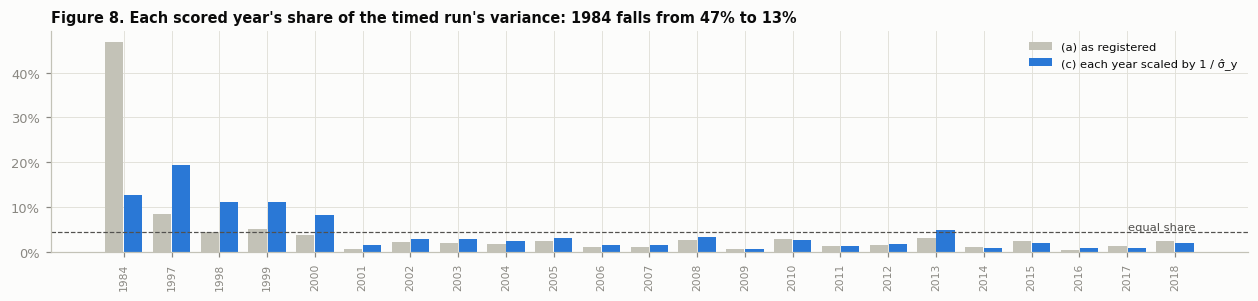

In [34]:
# Figure 8: each scored year's share of the timed run's pooled variance, before and after option (c)
fig, ax = plt.subplots(figsize=(11.5, 2.8))
x = np.arange(len(Y))
ax.bar(x - 0.2, Y["share_of_timed_variance: (a)"], width=0.38, color=AXIS, label="(a) as registered")
ax.bar(x + 0.2, Y["share_of_timed_variance: (c)"], width=0.38, color=BLUE, label="(c) each year scaled by 1 / σ̂_y")
ax.set_xticks(x, Y.index, fontsize=7, rotation=90)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.axhline(1 / len(Y), color=INK2, lw=0.8, ls="--")
ax.text(len(Y) - 0.5, 1 / len(Y), "equal share ", ha="right", va="bottom", fontsize=7.5, color=INK2)
ax.legend(fontsize=7.5, loc="upper right")
ax.set_title("Figure 8. Each scored year's share of the timed run's variance: 1984 falls from 47% to 13%")
fig.tight_layout()

**Reading.**

- **(c) reads "inconclusive" too:** +0.214, standard error 0.137, one-sided p 0.059, just above 5%. So (c) does not rescue the development result. Its minimum detectable effect is 0.34, against (a)'s 0.45.
- **It removes most of 1984's weight.**
  - Buy-and-hold: 1984's share of the variance falls from 15% to 3%.
  - The timed run: it falls from 47% to 13%.
  - Under (c), the largest year is 1997 (19%), not 1984.
  - 1984 still carries about three times an equal share, because the timed run itself levered to 1.5 that year. (c) scales by buy-and-hold's ex-ante risk on purpose: it does not undo what the timing chose.
- **It equalizes ex-ante risk, not realized risk.** 2000 and 2001 turned out about three times as volatile as their 10-year σ̂ (4.9%), and they carry 17–19% of buy-and-hold's variance under (c).
- **Its standard error (0.137) is close to the 1997–2018 cut's (0.134).** Once each year carries its own risk budget, the 12 months of 1984 no longer inflate the uncertainty, as your diagnosis in Entry 10 predicted.

## Using the robustness code

```python
from src.data.load import load_dev, load_etf_ohlc_dev
from src.engine.data import DAY
from src.robustness import checks, crises
from src.walkforward import runs, screened

panel, ohlc = load_dev(), load_etf_ohlc_dev()
surv = screened.survivors(screened.screen_all(panel, ohlc, jobs=-2))
rec = checks.recipes(panel, "screened", surv)                 # or checks.recipes(panel, "fixed"), drop="bab", ...
book, res, periods = checks.run(panel, rec, {"freq": DAY})    # one change: freq, window, max_size, rule, order or kappa
runs.metrics(res, periods, checks.whole_months(book, res))    # the robustness row

s = crises.span(panel, "2007", "2009")                        # the market's peak, trough and window
path = crises.path(book, res, periods)                        # day by day: value, size, forecast
crises.questions(path, s)                                     # before or after the worst days, the rebound
```

```bash
python -m src.robustness.build      # about 50 minutes on 10 cores the first time (new GARCH walk-forwards); a minute once cached
```